 # 🍽️ Zomato Data Analysis using Python

In [98]:
#Importing necessary Python libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [99]:
# Creating the data frame

df= pd.read_csv("Zomato_data.csv")
df.head(10)

,Name,Online_order,Book_table,Rate,Votes,Approx_Cost(for two people),Listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
5,Timepass Dinner,Yes,No,3.8/5,286,600,Buffet
6,Rosewood International Hotel - Bar & Restaurant,No,No,3.6/5,8,800,Buffet
7,Onesta,Yes,Yes,4.6/5,2556,600,Cafes
8,Penthouse Cafe,Yes,No,4.0/5,324,700,other
9,Smacznego,Yes,No,4.2/5,504,550,Cafes


In [100]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Name                         148 non-null    object
 1   Online_order                 148 non-null    object
 2   Book_table                   148 non-null    object
 3   Rate                         148 non-null    object
 4   Votes                        148 non-null    int64 
 5   Approx_Cost(for two people)  148 non-null    int64 
 6   Listed_in(type)              148 non-null    object
dtypes: int64(2), object(5)
memory usage: 8.2+ KB


(148, 7)

In [101]:
df.describe()

,Votes,Approx_Cost(for two people)
count,148.000000,148.000000
mean,264.810811,418.243243
std,653.676951,223.085098
min,0.000000,100.000000
25%,6.750000,200.000000
50%,43.500000,400.000000
75%,221.750000,600.000000
max,4884.000000,950.000000


In [102]:
# Data Cleaning and Preparation

def handleRate(value):
    value = str(value).split("/")
    value = value[0]
    return float(value)

df['Rate'] = df['Rate'].apply(handleRate)
df.head()

,Name,Online_order,Book_table,Rate,Votes,Approx_Cost(for two people),Listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [103]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Name                         148 non-null    object 
 1   Online_order                 148 non-null    object 
 2   Book_table                   148 non-null    object 
 3   Rate                         148 non-null    float64
 4   Votes                        148 non-null    int64  
 5   Approx_Cost(for two people)  148 non-null    int64  
 6   Listed_in(type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


In [104]:
# Checking for missing or null values to identify any data gaps

print(df.isnull().sum())

Name                           0
Online_order                   0
Book_table                     0
Rate                           0
Votes                          0
Approx_Cost(for two people)    0
Listed_in(type)                0
dtype: int64


# 📈 Exploratory Data Analysis

## 1. Restaurant Category Distribution

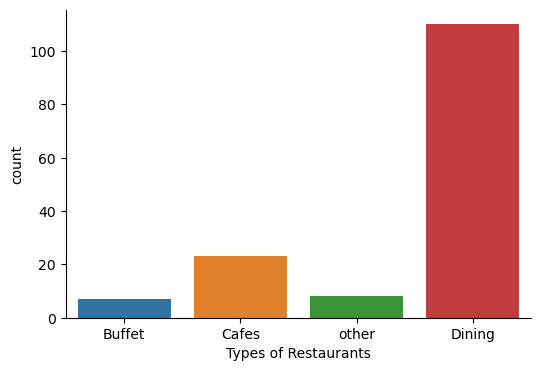

In [105]:
plt.figure(figsize = (6,4))
sns.countplot(x ='Listed_in(type)', data = df, hue = 'Listed_in(type)')
sns.despine()
plt.xlabel("Types of Restaurants")
plt.show()

**Conclusion:** The majority of the restaurants fall into the dining category.

## 2. Customer Votes by Restaurant Type

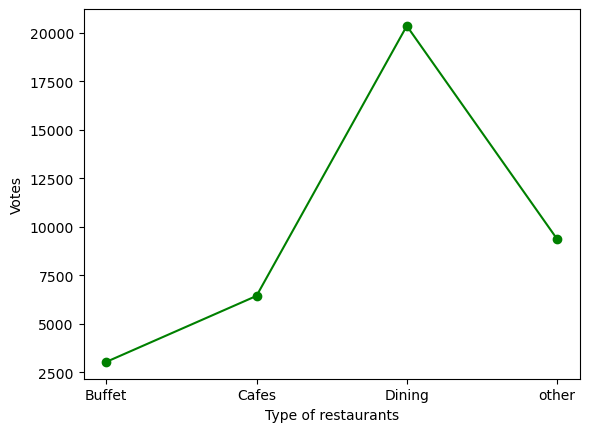

In [106]:
grouped_data = df.groupby('Listed_in(type)')['Votes'].sum()
result = pd.DataFrame({'Votes': grouped_data})   
plt.plot(result, color='green', marker='o')
plt.xlabel('Type of restaurants')
plt.ylabel('Votes')
plt.show()

**Conclusion:** Dining restaurants are preferred by a larger number of individuals.

## 3. Most Popular Restaurant

In [107]:
max_votes = df['Votes'].max()
restaurant_with_max_votes = df.loc[df['Votes'] == max_votes, 'Name']

print('Restaurant(s) with the maximum votes:')
print("\n",restaurant_with_max_votes)

Restaurant(s) with the maximum votes:

 38    Empire Restaurant
Name: Name, dtype: object


## 4. Online Ordering Analysis

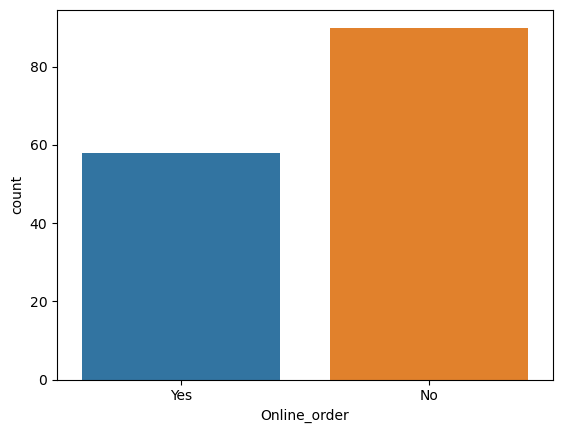

In [108]:
sns.countplot(x='Online_order',data = df, hue = 'Online_order')
plt.show()

**Conclusion:** This suggests that a majority of the restaurants do not accept online orders.

## 5. Ratings Distribution

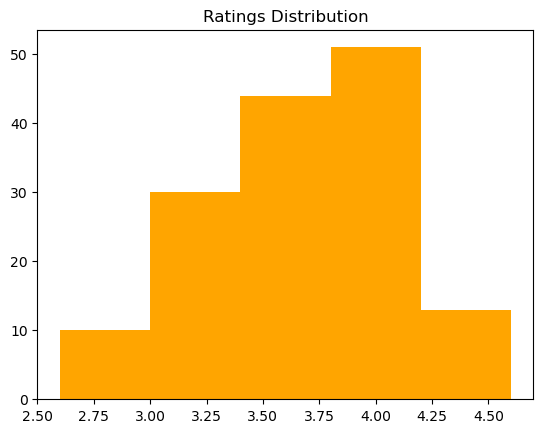

In [109]:
plt.hist(df['Rate'],bins=5,color = 'orange')
plt.title('Ratings Distribution')
plt.show()

**Conclusion:** The majority of restaurants received ratings ranging from 3.5 to 4.

## 6. Cost Preference Analysis

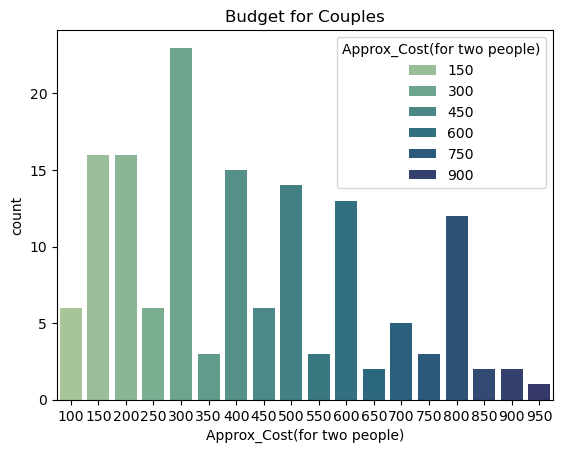

In [110]:
couple_data=df['Approx_Cost(for two people)']
sns.countplot(x=couple_data, hue = couple_data, palette = 'crest')
plt.title("Budget for Couples")
plt.show()

**Conclusion:** The majority of couples prefer restaurants with an approximate cost of 300 rupees.

## 7. Online vs Offline Rating Comparison

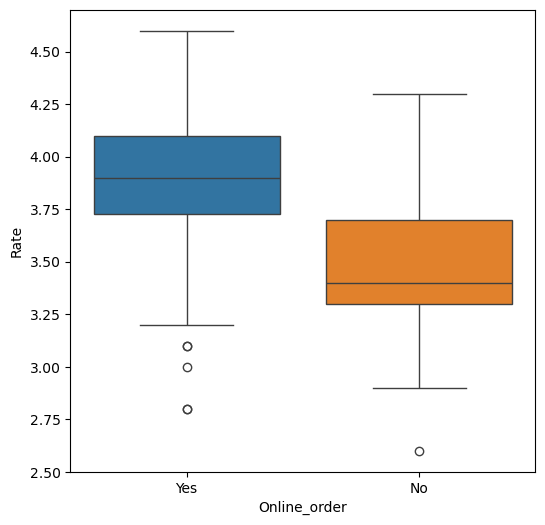

In [111]:
plt.figure(figsize = (6,6))
sns.boxplot(x = 'Online_order', y = 'Rate', data = df, hue = 'Online_order')
plt.show()

**Conclusion:** Offline orders received lower ratings in comparison to online orders which obtained excellent ratings.

## 8. Restaurant Type vs Order Mode

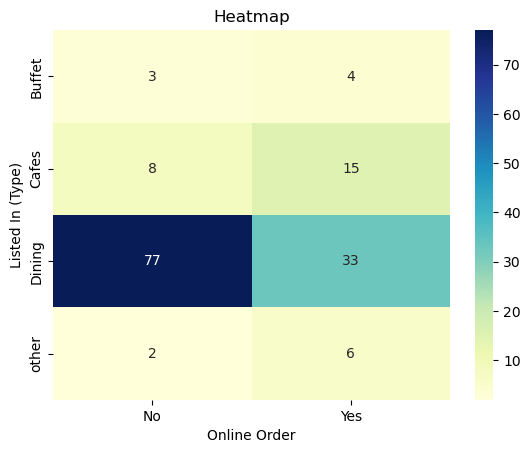

In [112]:
pivot_table = df.pivot_table(index='Listed_in(type)', columns='Online_order', aggfunc='size', fill_value=0)
sns.heatmap(pivot_table, annot=True, cmap='YlGnBu', fmt='d')
plt.title('Heatmap')
plt.xlabel('Online Order')
plt.ylabel('Listed In (Type)')
plt.show()

**Conclusion:** Dining restaurants heavily rely on offline customers. Cafes receive a higher percentage of online orders. Ordering preferences vary significantly across restaurant categories.